# load the data

In [14]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("janbrzozowski/webots")

print("Path to dataset files:", path)

Using Colab cache for faster access to the 'webots' dataset.
Path to dataset files: /kaggle/input/webots


In [15]:
import pandas as pd
import os

# The dataset was downloaded to the path stored in the 'path' variable from the previous cell.
# We need to construct the correct paths for the CSV files using this base path.

train_path = f'{path}/data_splits/train'
train_df = pd.read_csv(f'{train_path}/std_train_data.csv')


test_path = f'{path}/data_splits/test'
test_df = pd.read_csv(f'{test_path}/std_test_data.csv')
train_df

,Index,Steering,Speed
0,0,0.012245,1.838901
1,1,0.511877,0.147811
2,2,0.237326,1.319404
3,3,-1.714682,0.107679
4,4,-0.944547,0.014621
...,...,...,...
22850,22850,0.766957,0.031984
22851,22851,0.242109,0.430090
22852,22852,0.000706,0.826997
22853,22853,-0.208952,-0.303714


# Dataset class

In [16]:
from torch.utils.data import Dataset
from PIL import Image
import torch

class trafficSignDataset(Dataset):
    def __init__(self, df, root_dir, transform=None):
        self.df = df
        self.root_dir = root_dir
        self.transform = transform

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        row = self.df.iloc[idx]

        img_id = int(row['Index'])
        y1 = row['Steering']
        y2 = row['Speed']

        img_path = f'{self.root_dir}/{img_id}.png'
        image = Image.open(img_path).convert("RGB")

        if self.transform:
            image = self.transform(image)

        label = torch.tensor([y1, y2], dtype=torch.float32)

        return image, label

In [17]:
from torchvision import transforms
from torch.utils.data import DataLoader

transform = transforms.Compose([
    transforms.Resize((256, 256)),
    transforms.ColorJitter(brightness=0.2),
    transforms.ToTensor()
])

train_dir = '/kaggle/input/webots/data_splits/train/images'
test_dir = '/kaggle/input/webots/data_splits/test/images'

train_dataset = trafficSignDataset(train_df, train_dir, transform=transform)
test_dataset  = trafficSignDataset(test_df,  test_dir, transform=transform)

train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True)
test_loader  = DataLoader(test_dataset,  batch_size=32, shuffle=False)


print(f"Train: {len(train_dataset)}, Test: {len(test_dataset)}")

Train: 22855, Test: 4898


# display samples

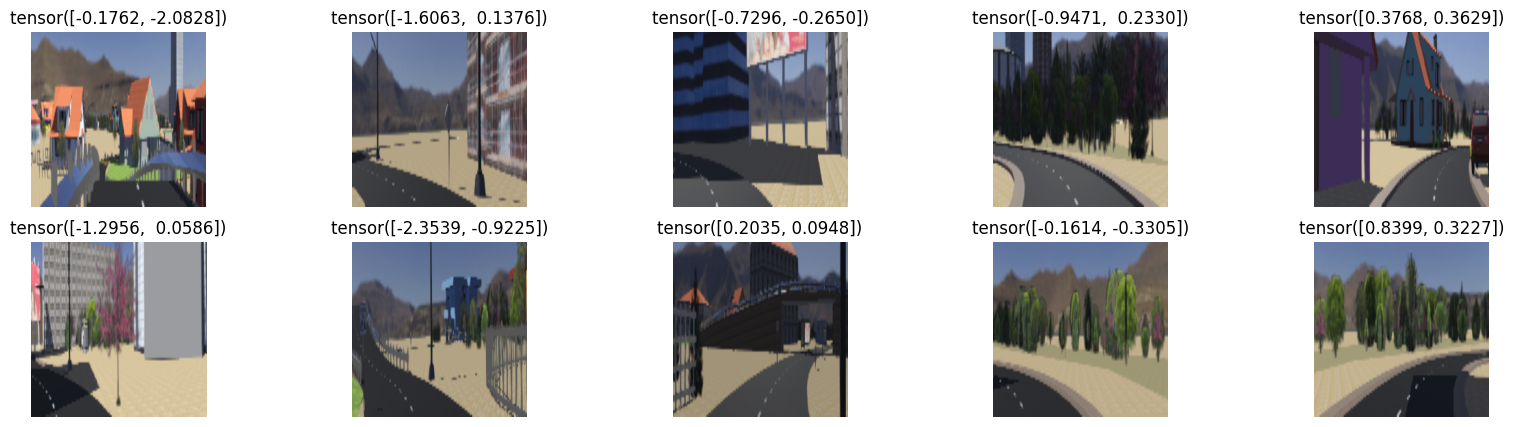

In [18]:
import matplotlib.pyplot as plt
import numpy as np

data_iter = iter(train_loader)
images, labels = next(data_iter)

fig, axes = plt.subplots(2, 5, figsize=(20, 5))
for i, ax in enumerate(axes.flat):
    img = images[i]
    label = labels[i]
    img = np.transpose(img.numpy(), (1, 2, 0))

    ax.imshow(img)
    ax.set_title(label)
    ax.axis("off")

plt.show()

# Model class

In [19]:
import torch.nn as nn
import torch

# CNN Model
class CNNModel(nn.Module):
    def __init__(self):
        super(CNNModel, self).__init__()

        # Convolutional Layers
        self.conv1 = nn.Conv2d(in_channels=3, out_channels=16, kernel_size=3, padding=1)
        self.conv2 = nn.Conv2d(in_channels=16, out_channels=32, kernel_size=3, padding=1)
        self.conv3 = nn.Conv2d(in_channels=32, out_channels=64, kernel_size=3, padding=1)
        self.conv4 = nn.Conv2d(in_channels=64, out_channels=96, kernel_size=3, padding=1)
        self.conv5 = nn.Conv2d(in_channels=96, out_channels=128, kernel_size=3, padding=1)

        self.bn1 = nn.BatchNorm2d(16)
        self.bn2 = nn.BatchNorm2d(32)
        self.bn3 = nn.BatchNorm2d(64)
        self.bn4 = nn.BatchNorm2d(96)
        self.bn5 = nn.BatchNorm2d(128)

        self.relu = nn.ReLU()
        self.pool = nn.MaxPool2d(kernel_size=2, stride=2)

        # Fully Connected Layers
        self.fc1 = nn.Linear(8192, 256) #128 * 8 * 8
        self.fc2 = nn.Linear(256, 2)

        self.dropout = nn.Dropout(0.3)

    def forward(self, x):
        # Conv + ReLU + Batch Normlization + Pooling
        x = self.pool(self.relu(self.bn1(self.conv1(x))))
        x = self.pool(self.relu(self.bn2(self.conv2(x))))
        x = self.pool(self.relu(self.bn3(self.conv3(x))))
        x = self.pool(self.relu(self.bn4(self.conv4(x))))
        x = self.pool(self.relu(self.bn5(self.conv5(x))))


        x = x.view(x.size(0), -1)  # flatten (Batch, everything else)

        x = self.relu(self.fc1(x))
        x = self.dropout(x)
        x = self.fc2(x)

        return x

# training loop

In [20]:
from tqdm import tqdm


def train_one_epoch(model, dataloader, criterion, optimizer, device):
    model.train()
    total_loss = 0
    total_mae = 0

    for images, labels in tqdm(dataloader):
        images, labels = images.to(device), labels.to(device).float()


        outputs = model(images)
        loss = criterion(outputs, labels)

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        total_loss += loss.item()


        mae = torch.mean(torch.abs(outputs - labels))
        total_mae += mae.item()

    avg_loss = total_loss / len(dataloader)
    avg_mae = total_mae / len(dataloader)
    return avg_loss, avg_mae

# validation loop

In [21]:
def validate(model, dataloader, criterion, device):
    model.eval()
    total_loss = 0
    total_mae = 0

    with torch.no_grad():
        for images, labels in dataloader:
            images, labels = images.to(device), labels.to(device).float()

            outputs = model(images)
            loss = criterion(outputs, labels)
            total_loss += loss.item()

            mae = torch.mean(torch.abs(outputs - labels))
            total_mae += mae.item()

    avg_loss = total_loss / len(dataloader)
    avg_mae = total_mae / len(dataloader)
    return avg_loss, avg_mae


# running training

In [22]:
import torch.optim as optim

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model = CNNModel().to(device)

criterion = nn.SmoothL1Loss()
optimizer = optim.Adam(model.parameters(), lr=1e-4)
num_epochs = 10


train_losses = []
val_losses = []
train_maes = []
val_maes = []


for epoch in range(num_epochs):
    train_loss, train_mae = train_one_epoch(model, train_loader, criterion, optimizer, device)
    val_loss, val_mae = validate(model, test_loader, criterion, device)

    train_losses.append(train_loss)
    val_losses.append(val_loss)
    train_maes.append(train_mae)
    val_maes.append(val_mae)

    print(f"Epoch {epoch+1}/{num_epochs}: "
          f"Train Loss={train_loss:.4f}, Train MAE={train_mae:.4f}, "
          f"Val Loss={val_loss:.4f}, Val MAE={val_mae:.4f}")

100%|██████████| 715/715 [03:14<00:00,  3.67it/s]


Epoch 1/10: Train Loss=0.1167, Train MAE=0.3607, Val Loss=0.0507, Val MAE=0.2376


100%|██████████| 715/715 [02:06<00:00,  5.66it/s]


Epoch 2/10: Train Loss=0.0527, Train MAE=0.2411, Val Loss=0.0367, Val MAE=0.1925


100%|██████████| 715/715 [02:10<00:00,  5.49it/s]


...

Epoch 8/10: Train Loss=0.0300, Train MAE=0.1802, Val Loss=0.0219, Val MAE=0.1531


100%|██████████| 715/715 [02:06<00:00,  5.66it/s]


Epoch 9/10: Train Loss=0.0288, Train MAE=0.1764, Val Loss=0.0233, Val MAE=0.1522


100%|██████████| 715/715 [02:05<00:00,  5.68it/s]


Epoch 10/10: Train Loss=0.0268, Train MAE=0.1696, Val Loss=0.0180, Val MAE=0.1318


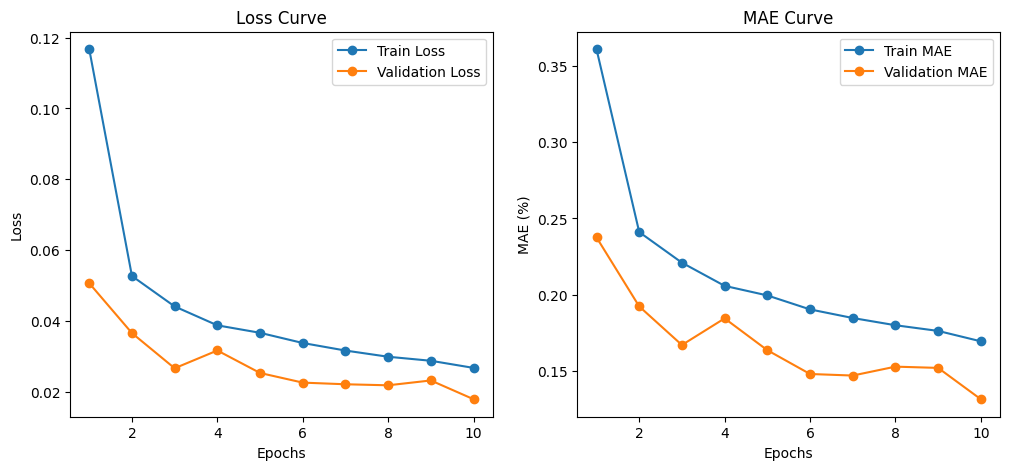

In [23]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
plt.plot(range(1, num_epochs+1), train_losses, label="Train Loss", marker='o')
plt.plot(range(1, num_epochs+1), val_losses, label="Validation Loss", marker='o')
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.title("Loss Curve")
plt.legend()


plt.subplot(1, 2, 2)
plt.plot(range(1, num_epochs+1), train_maes, label="Train MAE", marker='o')
plt.plot(range(1, num_epochs+1), val_maes, label="Validation MAE", marker='o')
plt.xlabel("Epochs")
plt.ylabel("MAE (%)")
plt.title("MAE Curve")
plt.legend()

plt.show()


# Save Results

In [25]:
# save model's state
torch.save(model, 'CNN model.pt')

torch.save(model.state_dict(), "cnn_project.pth")

# Webots Controller

### Do not run the cells bellow

In [ ]:
from vehicle import Driver
import numpy as np
import cv2
import torch
import torch.nn as nn


# CNN Regression Model

class CNNModel(nn.Module):
    def __init__(self):
        super(CNNModel, self).__init__()

        self.conv1 = nn.Conv2d(3, 16, 3, padding=1)
        self.conv2 = nn.Conv2d(16, 32, 3, padding=1)
        self.conv3 = nn.Conv2d(32, 64, 3, padding=1)
        self.conv4 = nn.Conv2d(64, 96, 3, padding=1)
        self.conv5 = nn.Conv2d(96, 128, 3, padding=1)

        self.bn1 = nn.BatchNorm2d(16)
        self.bn2 = nn.BatchNorm2d(32)
        self.bn3 = nn.BatchNorm2d(64)
        self.bn4 = nn.BatchNorm2d(96)
        self.bn5 = nn.BatchNorm2d(128)

        self.relu = nn.ReLU()
        self.pool = nn.MaxPool2d(2, 2)

        self.fc1 = nn.Linear(8192, 256)
        self.fc2 = nn.Linear(256, 2)

        self.dropout = nn.Dropout(0.3)

    def forward(self, x):
        x = self.pool(self.relu(self.bn1(self.conv1(x))))
        x = self.pool(self.relu(self.bn2(self.conv2(x))))
        x = self.pool(self.relu(self.bn3(self.conv3(x))))
        x = self.pool(self.relu(self.bn4(self.conv4(x))))
        x = self.pool(self.relu(self.bn5(self.conv5(x))))

        x = x.view(x.size(0), -1)

        x = self.relu(self.fc1(x))
        x = self.dropout(x)
        x = self.fc2(x)

        return x



# Preprocessing


def preprocess(frame):
    frame = cv2.resize(frame, (256, 256))
    frame = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
    frame = frame.astype(np.float32) / 255.0
    frame = np.transpose(frame, (2, 0, 1))
    return torch.tensor(frame, dtype=torch.float32).unsqueeze(0)



# Load Model


device = torch.device("cpu")

model = CNNModel().to(device)
model.load_state_dict(torch.load("cnn_project.pth", map_location=device))
model.eval()

print("Model loaded successfully.")



# Webots Driver Setup


driver = Driver()
timestep = int(driver.getBasicTimeStep())

camera = driver.getDevice("camera")
camera.enable(timestep)

width = camera.getWidth()
height = camera.getHeight()

print("Camera initialized:", width, "x", height)


# Main Control Loop


while driver.step() != -1:

    image = camera.getImageArray()
    if image is None:
        continue

    frame = np.array(image, dtype=np.uint8)  # shape (H, W, 3)

    x = preprocess(frame).to(device)

    with torch.no_grad():
        output = model(x).cpu().numpy()[0]

    steering = float(output[0])
    speed = abs(float(output[1])) * 100


    # Safety limits
    steering = max(min(steering, 0.5), -0.5)
    speed = max(min(speed, 80.0), 10.0)

    driver.setSteeringAngle(steering)
    driver.setCruisingSpeed(speed)

    print(f"Steering: {steering:.3f}, Speed: {speed:.3f}")